# Reusing a Fault-Diagnosis Model on a New Machine Variant
### Parameter transfer for Bayesian networks with little target data

**Research question.** A Bayesian network already diagnoses faults on machine A. A related machine B is introduced, with the same components and wiring but different fault rates and less reliable sensors, and only a handful of fault records are available for it. Should B's diagnosis model

1. **reuse A's model unchanged** (*source only*),
2. **be learned from B's data alone** (*from scratch*), or
3. **be learned from B's data with A's model as a prior** (*transfer*)?

And how much should A's model be trusted?

**Approach.**
- **Network:** `win95pts`, a 76-node printer-troubleshooting Bayesian network (26 root-cause faults, symptoms and diagnostic tests) from the bnlearn repository.
- **New machines:** two *synthetic* variants of the same structure, one mildly and one strongly different from A (section 2 explains what they represent and what they don't).
- **Two evaluations:** (1) how accurately each approach recovers B's true probabilities, and (2) how well it **diagnoses**: with the faults hidden, can it identify the single active fault from symptoms and test readings? Diagnosis uses exact posteriors over single-fault hypotheses, matching how the test cases are generated.
- **Robustness:** every experiment is repeated over 10 independent seeds, and uncertainty is reported as 95% confidence intervals *across seeds*. Methods are compared pairwise on identical data and test cases.
- **Reproducibility:** all randomness is seeded, the notebook runs top to bottom from a fresh kernel, and the findings in section 7 are **generated from the result tables**, not written by hand.

**Scope.** Both machines share the same graph, so this studies *parameter* transfer. Structural changes are discussed under next steps.

## 0. Setup

In [1]:
import warnings, logging, time, itertools
warnings.filterwarnings("ignore")
logging.getLogger("pgmpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import logsumexp
from joblib import Parallel, delayed
from IPython.display import display, Markdown

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

pd.set_option("display.width", 140)

# ---------------- Experiment settings ----------------
VARIANTS = {                        # how strongly machine B differs from machine A
    "mild":   dict(fault_rate_spread=0.5, sensor_noise=0.03),
    "strong": dict(fault_rate_spread=1.2, sensor_noise=0.15),
}
TRAIN_SIZES  = [25, 50, 100, 250, 1000, 5000]   # fault records available for machine B
DIAG_SIZES   = [25, 50, 100, 250, 1000]         # training sizes used in the diagnosis experiment
SEEDS        = list(range(10))                  # independent repetitions of every experiment
N_TEST_CASES = 200                              # single-fault test cases per seed
PRIOR_ESS    = 10                               # transfer: virtual records per parent configuration
N_JOBS       = -1                               # parallel workers (-1 = all CPU cores)

COLORS = {"source only": "tab:gray", "from scratch": "tab:orange",
          "transfer": "tab:green", "true model (reference)": "black"}

## 1. Load the network and identify node roles

Every root node of `win95pts` is a possible cause. Most are **faults** (a loose cable, a corrupt driver, no paper), but a few describe the **setup** rather than a fault (DOS vs Windows, network vs local printer). Those *context* nodes are hidden during diagnosis but are never counted as faults. All non-root nodes are **observations**: user-visible symptoms and the readings of diagnostic tests.

In [2]:
try:
    from pgmpy.example_models import load_model
    source = load_model("bnlearn/win95pts")
except ImportError:                       # older pgmpy versions
    from pgmpy.utils import get_example_model
    source = get_example_model("win95pts")

STATES = {n: source.get_cpds(n).state_names[n] for n in source.nodes()}   # fixed state order everywhere
STATE_INDEX = {n: {s: i for i, s in enumerate(states)} for n, states in STATES.items()}

CONTEXT = ["DSApplctn", "NetPrint", "PrtPScript", "TrTypFnts", "PrntrAccptsTrtyp",
           "EPSGrphc", "PrtThread", "ScrnFntNtPrntrFnt"]
ROOTS    = [n for n in source.nodes() if source.in_degree(n) == 0]
FAULTS   = [r for r in ROOTS if r not in CONTEXT]
FAULTY   = {f: STATES[f][1] for f in FAULTS}          # the second state is the faulty one for every fault
OBSERVED = [n for n in source.nodes() if source.in_degree(n) > 0]
assert set(ROOTS) == set(FAULTS) | set(CONTEXT)

print(f"{len(source.nodes())} nodes, {len(source.edges())} edges, "
      f"max {max(source.in_degree(n) for n in source.nodes())} parents per node")
print(f"{len(FAULTS)} faults | {len(CONTEXT)} hidden context nodes | {len(OBSERVED)} observed symptoms and tests")

fault_table = pd.DataFrame({"faulty state": FAULTY,
                            "P(fault) on machine A": {f: source.get_cpds(f).get_value(**{f: FAULTY[f]}) for f in FAULTS}})
display(fault_table.sort_values("P(fault) on machine A", ascending=False).round(3).head(8))

76 nodes, 112 edges, max 7 parents per node
26 faults | 8 hidden context nodes | 42 observed symptoms and tests


,faulty state,P(fault) on machine A
PTROFFLINE,Offline,0.30
PrtMpTPth,Incorrect,0.20
FllCrrptdBffr,Full_or_Corrupt,0.15
PrtDriver,No,0.10
PrtOn,No,0.10
PrtTimeOut,Too_Short,0.06
PrtSpool,Disabled,0.05
PrtMem,Less_than_2Mb,0.05


## 2. Simulate the new machines

**These variants are synthetic, controlled perturbations, not measurements of real machines.** They are designed to isolate two mechanisms that plausibly differ between machine variants, so that their effect on transfer can be studied in a setting where the true answer is known:

- **Different fault rates.** Usage patterns, environment and component suppliers change how often each fault occurs. Each fault's probability is multiplied by a random factor $e^{z}$, $z \sim \mathcal{N}(0, \sigma)$ (capped at 0.5).
- **Less reliable sensors and tests.** Different hardware, ageing or calibration make observations noisier. Every non-root table is blended with random noise: $P_B = (1-\lambda)\,P_A + \lambda\,\text{noise}$. A test that always read "OK" when nothing was wrong now occasionally doesn't, and deterministic relations in A become slightly uncertain in B.

**Why these two levels.**
- **Mild** ($\sigma = 0.5$, $\lambda = 0.03$): a typical fault rate changes by a factor of about 1.4 and sensors are almost unchanged, like a minor revision of the same product line. Here A's model should be nearly right, so the question is whether B's few records add anything.
- **Strong** ($\sigma = 1.2$, $\lambda = 0.15$): a typical fault rate changes by a factor of about 2.2 (some by 10× or more) and sensors are noticeably less reliable, like the same design in a very different operating context. Here A's model is clearly wrong, so the question is whether it is still a useful starting point.

(A typical factor is $e^{0.674\sigma}$, the median of $e^{|z|}$.)

**What is *not* modelled:** structural changes (new or removed components), correlated or systematic changes (e.g. every sensor drifting in the same direction), and changes over time. The measured differences actually produced are reported in the table below.

,median fault-rate change (×),max fault-rate change (×),mean sensor-table change (TV distance),A's impossible entries now possible
mild,1.42876,3.395887,0.010958,224/224
strong,2.151136,17.446215,0.054792,224/224


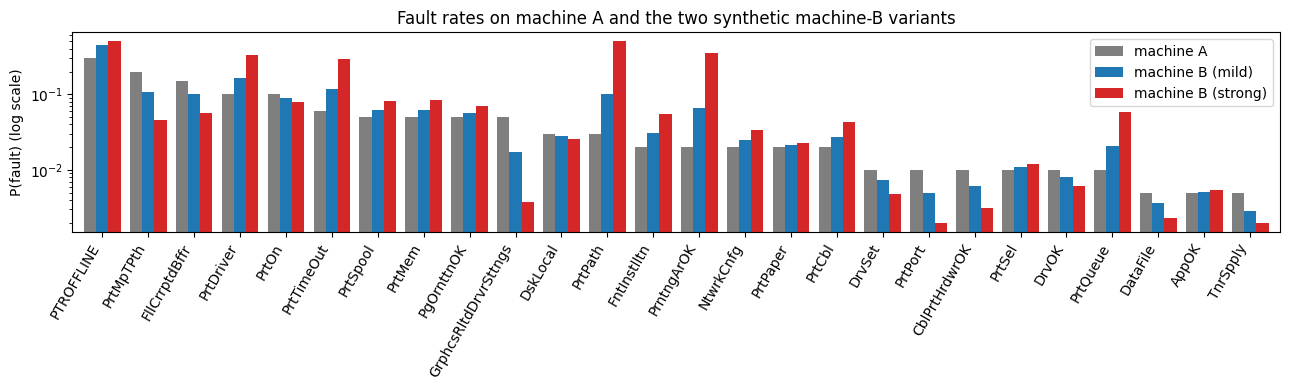

In [3]:
def make_variant(model, fault_rate_spread, sensor_noise, seed=42):
    rng = np.random.default_rng(seed)
    cpds = []
    for cpd in model.get_cpds():
        node, values, parents = cpd.variable, cpd.get_values().copy(), cpd.variables[1:]
        if node in FAULTS:
            p = values[1, 0] * np.exp(rng.normal(0, fault_rate_spread))
            p = float(np.clip(p, 0.002, 0.5))
            values = np.array([[1 - p], [p]])
        elif node not in CONTEXT:
            noise = rng.dirichlet(np.ones(values.shape[0]), size=values.shape[1]).T
            values = (1 - sensor_noise) * values + sensor_noise * noise
        cpds.append(TabularCPD(node, values.shape[0], values,
                               evidence=parents or None,
                               evidence_card=[len(STATES[p]) for p in parents] or None,
                               state_names={v: STATES[v] for v in cpd.variables}))
    variant = DiscreteBayesianNetwork(model.edges())
    variant.add_nodes_from(model.nodes())
    variant.add_cpds(*cpds)
    assert variant.check_model()
    return variant


targets = {name: make_variant(source, **cfg) for name, cfg in VARIANTS.items()}


def describe_difference(model):
    fold = np.array([model.get_cpds(f).get_value(**{f: FAULTY[f]}) / source.get_cpds(f).get_value(**{f: FAULTY[f]})
                     for f in FAULTS])
    fold = np.maximum(fold, 1 / fold)                       # symmetric: 2x rarer counts like 2x more common
    tv, zeros_lost, zeros = [], 0, 0
    for node in OBSERVED:
        a, b = source.get_cpds(node).get_values(), model.get_cpds(node).get_values()
        tv.extend(0.5 * np.abs(a - b).sum(axis=0))          # total variation distance per table column
        zeros += (a == 0).sum(); zeros_lost += ((a == 0) & (b > 0)).sum()
    return {"median fault-rate change (×)": np.median(fold), "max fault-rate change (×)": fold.max(),
            "mean sensor-table change (TV distance)": np.mean(tv),
            "A's impossible entries now possible": f"{zeros_lost}/{zeros}"}

display(pd.DataFrame({name: describe_difference(m) for name, m in targets.items()}).T)

rates = pd.DataFrame({"machine A": fault_table["P(fault) on machine A"]})
for name, model in targets.items():
    rates[f"machine B ({name})"] = [model.get_cpds(f).get_value(**{f: FAULTY[f]}) for f in rates.index]
rates = rates.sort_values("machine A", ascending=False)
ax = rates.plot(kind="bar", figsize=(13, 4), logy=True, width=0.8, color=["tab:gray", "tab:blue", "tab:red"])
ax.set_ylabel("P(fault) (log scale)"); ax.set_title("Fault rates on machine A and the two synthetic machine-B variants")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

## 3. The three approaches

| Approach | Uses | How |
|---|---|---|
| **Source only** | machine A's model | Reused unchanged; needs no data from B. |
| **From scratch** | B's data | Bayesian estimation with a weak uniform prior (K2: one virtual count per cell), so unseen combinations don't get probability zero. |
| **Transfer** | B's data + A's model | The same estimator as *from scratch*, plus A's probabilities as extra Dirichlet pseudo-counts: for every parent combination, A's table counts as `PRIOR_ESS` virtual records added to B's real counts. With little data the estimate stays close to A; with lots of data B's own counts dominate. The only difference from *from scratch* is the transferred knowledge. |

Two implementation details matter for correctness:
- **State names are fixed from the source model.** Otherwise pgmpy infers states from the data, so a rare state missing from a small sample silently changes the table's shape, and states may be reordered alphabetically.
- **Tables are aligned before comparing or combining them.** pgmpy orders a learned table's parents alphabetically, which can differ from the source table, so columns are rearranged explicitly.

In [4]:
def aligned_values(cpd, parent_order):
    # CPD values with columns arranged in the given parent order
    cpd = cpd.copy()
    if len(parent_order) > 1:
        cpd.reorder_parents(list(parent_order), inplace=True)
    return cpd.get_values()


def empty_model():
    model = DiscreteBayesianNetwork(source.edges())
    model.add_nodes_from(source.nodes())
    return model


def learn_from_scratch(data):
    model = empty_model()
    estimator = BayesianEstimator(model, data, state_names=STATES)
    model.add_cpds(*[estimator.estimate_cpd(n, prior_type="K2") for n in model.nodes()])
    return model


def learn_with_transfer(data, prior_ess=PRIOR_ESS):
    model = empty_model()
    estimator = BayesianEstimator(model, data, state_names=STATES)
    cpds = []
    for node in model.nodes():
        source_table = aligned_values(source.get_cpds(node), sorted(model.get_parents(node)))
        prior = 1 + prior_ess * source_table      # same K2 base as 'from scratch', plus A's knowledge
        cpds.append(estimator.estimate_cpd(node, prior_type="dirichlet", pseudo_counts=prior))
    model.add_cpds(*cpds)
    return model


def simulate(model, n, seed):
    return model.simulate(n_samples=n, seed=seed, show_progress=False)


def mean_ci(x):
    # Mean and 95% confidence half-width across independent seeds (t-distribution)
    x = np.asarray(x, dtype=float)
    half = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0.0
    return pd.Series({"mean": x.mean(), "ci": half})


def fmt(m, ci, digits=3):
    return f"{m:.{digits}f} ± {ci:.{digits}f}"

## 4. Experiment 1: how well is machine B's model recovered?

A plain average of squared errors over every table column treats a parent combination that occurs once in a million cases the same as one that occurs every day, so rare, practically irrelevant combinations dominate. Instead, each column's error is **weighted by how often that parent combination actually occurs on machine B**, computed exactly with inference on B's true model:

$$\text{error} = \frac{1}{|V|}\sum_{X \in V} \; \sum_{\text{pa}} P_B(\text{pa}) \cdot \text{mean}_x \big(P_B(x\mid \text{pa}) - \hat P(x\mid \text{pa})\big)^2$$

In [5]:
def parent_weights(true_model):
    # For each node: probability of every parent combination, in the column order of its CPD
    ve, weights = VariableElimination(true_model), {}
    for node in true_model.nodes():
        parents = true_model.get_cpds(node).variables[1:]
        if not parents:
            weights[node] = np.array([1.0]); continue
        joint = ve.query(list(parents), show_progress=False)
        values = np.transpose(joint.values, [joint.variables.index(p) for p in parents])
        for i, p in enumerate(parents):                       # make sure states are in CPD order
            values = np.take(values, [joint.state_names[p].index(s) for s in STATES[p]], axis=i)
        weights[node] = values.reshape(-1)
    return weights


def weighted_error(estimated, true_model, weights):
    errors = []
    for node in true_model.nodes():
        true_cpd = true_model.get_cpds(node)
        est = aligned_values(estimated.get_cpds(node), true_cpd.variables[1:])
        column_mse = ((true_cpd.get_values() - est) ** 2).mean(axis=0)
        errors.append(np.sum(weights[node] * column_mse))
    return float(np.mean(errors))


WEIGHTS = {name: parent_weights(model) for name, model in targets.items()}

**Sanity checks.** Before trusting any comparison, the pipeline must pass three checks: the weights form probability distributions, a model compared with itself has zero error, and learning from a very large sample recovers the true model with both methods.

In [6]:
big = simulate(targets["strong"], 200_000, seed=999)
w = WEIGHTS["strong"]
sanity = pd.DataFrame({"result": {
    "weights sum to 1":                     all(np.isclose(v.sum(), 1) for v in w.values()),
    "error(true model, itself) == 0":       weighted_error(targets["strong"], targets["strong"], w) == 0,
    "from scratch, 200k records: error":    f"{weighted_error(learn_from_scratch(big), targets['strong'], w):.6f}",
    "transfer, 200k records: error":        f"{weighted_error(learn_with_transfer(big), targets['strong'], w):.6f}",
    "source only: error (for comparison)":  f"{weighted_error(source, targets['strong'], w):.6f}",
}})
display(sanity)

,result
weights sum to 1,True
"error(true model, itself) == 0",True
"from scratch, 200k records: error",0.000004
"transfer, 200k records: error",0.000004
source only: error (for comparison),0.010415


Experiment 1: 120 seed × size runs in 98s


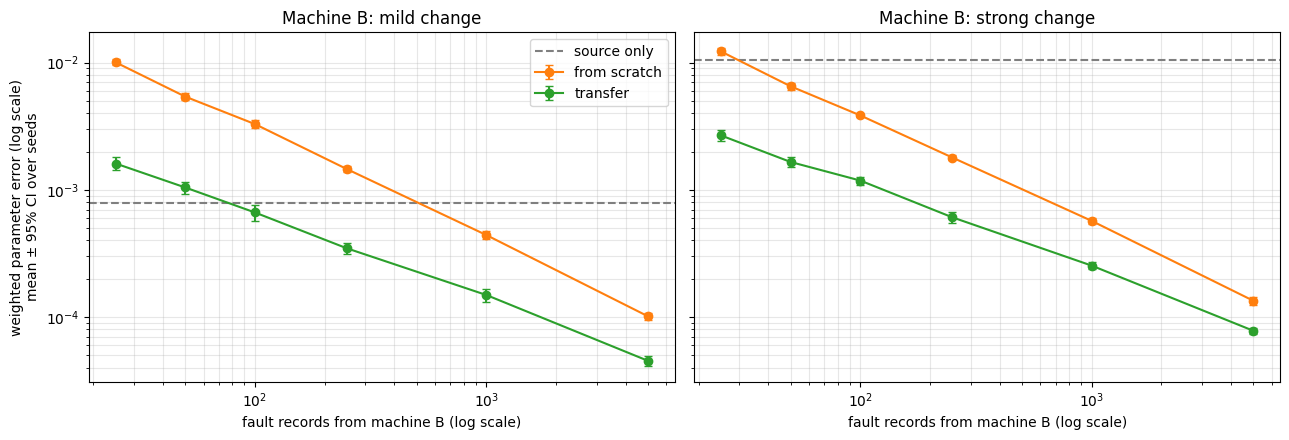

In [7]:
def param_job(variant, n, seed):
    data = simulate(targets[variant], n, seed)
    w, true = WEIGHTS[variant], targets[variant]
    return [{"variant": variant, "n": n, "seed": seed, "method": "from scratch",
             "error": weighted_error(learn_from_scratch(data), true, w)},
            {"variant": variant, "n": n, "seed": seed, "method": "transfer",
             "error": weighted_error(learn_with_transfer(data), true, w)}]

t0 = time.time()
rows = Parallel(n_jobs=N_JOBS)(delayed(param_job)(v, n, s) for v in VARIANTS for n in TRAIN_SIZES for s in SEEDS)
param_results = pd.DataFrame([r for pair in rows for r in pair])
source_error = {v: weighted_error(source, targets[v], WEIGHTS[v]) for v in VARIANTS}
print(f"Experiment 1: {len(rows)} seed × size runs in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, variant in zip(axes, VARIANTS):
    for method in ["from scratch", "transfer"]:
        g = param_results.query("variant == @variant and method == @method").groupby("n")["error"].apply(mean_ci).unstack()
        ax.errorbar(g.index, g["mean"], yerr=g["ci"], marker="o", capsize=3, color=COLORS[method], label=method)
    ax.axhline(source_error[variant], ls="--", color=COLORS["source only"], label="source only")
    ax.set(xscale="log", yscale="log", title=f"Machine B: {variant} change",
           xlabel="fault records from machine B (log scale)")
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("weighted parameter error (log scale)\nmean ± 95% CI over seeds")
axes[0].legend(); plt.tight_layout(); plt.show()

**Result table, experiment 1.** Mean ± 95% CI across seeds. The ratio is computed per seed (transfer and from scratch use the same data) and then averaged.

In [8]:
wide = param_results.pivot_table(index=["variant", "n", "seed"], columns="method", values="error")
wide["ratio"] = wide["transfer"] / wide["from scratch"]
param_table = (wide.groupby(["variant", "n"])
               .agg(lambda col: fmt(*mean_ci(col), digits=5))
               .rename(columns={"ratio": "transfer / scratch"}))
param_table["transfer / scratch"] = (wide.groupby(["variant", "n"])["ratio"]
                                     .apply(lambda c: fmt(*mean_ci(c), digits=2)))
param_table["source only"] = [f"{source_error[v]:.5f}" for v, _ in param_table.index]
param_table = param_table[["source only", "from scratch", "transfer", "transfer / scratch"]]
param_table

method       source only       from scratch           transfer transfer / scratch
variant n                                                                        
mild    25       0.00078  0.01007 ± 0.00055  0.00161 ± 0.00019        0.16 ± 0.01
        50       0.00078  0.00541 ± 0.00036  0.00104 ± 0.00012        0.19 ± 0.02
        100      0.00078  0.00329 ± 0.00023  0.00066 ± 0.00010        0.20 ± 0.03
        250      0.00078  0.00146 ± 0.00008  0.00035 ± 0.00003        0.24 ± 0.02
        1000     0.00078  0.00044 ± 0.00003  0.00015 ± 0.00002        0.34 ± 0.03
        5000     0.00078  0.00010 ± 0.00001  0.00005 ± 0.00000        0.45 ± 0.02
strong  25       0.01042  0.01224 ± 0.00074  0.00268 ± 0.00025        0.22 ± 0.02
        50       0.01042  0.00652 ± 0.00039  0.00166 ± 0.00015        0.25 ± 0.01
        100      0.01042  0.00385 ± 0.00010  0.00118 ± 0.00009        0.31 ± 0.02
        250      0.01042  0.00179 ± 0.00008  0.00061 ± 0.00006        0.34 ± 0.03
        1000     0.01042  0.00057 ± 0.00003  0.00025 ± 0.00002        0.45 ± 0.02
        5000     0.01042  0.00013 ± 0.00001  0.00008 ± 0.00000        0.58 ± 0.02

## 5. Experiment 2: can each model diagnose machine B?

Parameter error is a proxy. What matters in the field is **diagnosis**: a fault occurs, the engineer sees symptoms and test readings, and the model has to point at the cause.

**Test cases.** For each seed, cases are drawn from machine B's true model and only those with **exactly one active fault** are kept. The test distribution is therefore $P_B(\,\cdot \mid \text{exactly one fault})$.

**Inference matches the test assumption.** Each model scores the 26 *single-fault hypotheses* $H_f$ = "fault $f$ is active and every other fault is absent":

$$P(H_f \mid e) \;\propto\; P(H_f)\sum_{c} P(c)\, P(e \mid H_f, c),$$

where $e$ are the observed symptoms and tests and $c$ ranges over the $2^8$ configurations of the hidden context nodes. Because every non-root node is observed, $P(e \mid H_f, c)$ is just a product of table entries, so this posterior is **exact** and cheap to compute (vectorised over all hypotheses and contexts). Faults are ranked by $P(H_f \mid e)$, and **top-1** and **top-3** accuracy are scored.

**Reference benchmark.** Machine B's true model, scored the same way, gives the Bayes-optimal ranking for this test distribution: no model can have higher *expected* top-k accuracy. On a finite test set another model can still match or slightly exceed it by chance, so it is reported as a reference, not a hard ceiling. If a model assigns probability zero to every hypothesis (possible for *source only*, whose hard zeros B's noisier sensors violate), the case counts as a miss and is reported.

In [9]:
class SingleFaultDiagnoser:
    # Exact posterior over single-fault hypotheses, given all non-root nodes as evidence

    def __init__(self, model):
        roots = FAULTS + CONTEXT
        col = {r: i for i, r in enumerate(roots)}
        contexts = np.array(list(itertools.product(*[range(len(STATES[c])) for c in CONTEXT])))
        n_h, n_c = len(FAULTS), len(contexts)
        fault_states = np.repeat(np.eye(n_h, dtype=int), n_c, axis=0)       # hypothesis h: only fault h active
        self.root_states = np.hstack([fault_states, np.tile(contexts, (n_h, 1))])
        self.shape = (n_h, n_c)
        with np.errstate(divide="ignore"):
            self.log_prior = sum(np.log(model.get_cpds(r).get_values()[:, 0])[self.root_states[:, col[r]]]
                                 for r in roots)
            self.tables = []
            for node in OBSERVED:
                cpd = model.get_cpds(node)
                values = np.log(cpd.values)                     # axes: node, then parents in CPD order
                parents = cpd.variables[1:]
                self.tables.append((node, values, [(p, col.get(p)) for p in parents]))
        # state order of every table follows STATES (fixed when the CPDs were built or learned)
        for node, _, parents in self.tables[:3]:
            assert model.get_cpds(node).state_names[node] == STATES[node]

    def posterior(self, evidence):
        log_joint = self.log_prior.copy()
        for node, values, parents in self.tables:
            index = [STATE_INDEX[node][evidence[node]]]
            for p, root_col in parents:
                index.append(self.root_states[:, root_col] if root_col is not None
                             else STATE_INDEX[p][evidence[p]])
            log_joint = log_joint + values[tuple(index)]
        log_h = logsumexp(log_joint.reshape(self.shape), axis=1)          # sum over hidden contexts
        if not np.isfinite(log_h).any():
            return None                                                   # evidence impossible under this model
        return pd.Series(np.exp(log_h - logsumexp(log_h)), index=FAULTS)


def single_fault_cases(model, n, seed):
    parts, s = [], seed
    while sum(len(p) for p in parts) < n:
        d = simulate(model, 20 * n, s); s += 1_000
        n_faults = sum((d[f] == FAULTY[f]).astype(int) for f in FAULTS)
        parts.append(d[n_faults == 1])
    cases = pd.concat(parts).iloc[:n].reset_index(drop=True)
    cases["true_fault"] = cases[FAULTS].apply(lambda r: next(f for f in FAULTS if r[f] == FAULTY[f]), axis=1)
    return cases


def evaluate_diagnosis(model, cases):
    diagnoser, hits1, hits3, impossible = SingleFaultDiagnoser(model), [], [], 0
    for _, row in cases.iterrows():
        post = diagnoser.posterior(row)
        if post is None:
            impossible += 1; hits1.append(False); hits3.append(False); continue
        ranking = post.sort_values(ascending=False).index
        hits1.append(row.true_fault == ranking[0]); hits3.append(row.true_fault in ranking[:3])
    return np.mean(hits1), np.mean(hits3), impossible / len(cases)

**Validating the inference.** The fast posterior is checked against pgmpy's own probability computation (`get_state_probability`, which sums over every hidden context configuration independently). For a few test cases and hypotheses, the joint probability $P(e, H_f)$ must agree.

In [10]:
check_cases = single_fault_cases(targets["strong"], 3, seed=321)
diagnoser = SingleFaultDiagnoser(targets["strong"])
rows = []
for _, case in check_cases.iterrows():
    log_joint = diagnoser.log_prior.copy()
    for node, values, parents in diagnoser.tables:
        idx = [STATE_INDEX[node][case[node]]] + [diagnoser.root_states[:, c] if c is not None
                                                 else STATE_INDEX[p][case[p]] for p, c in parents]
        log_joint = log_joint + values[tuple(idx)]
    fast = logsumexp(log_joint.reshape(diagnoser.shape), axis=1)
    for f in [case.true_fault, FAULTS[0]]:
        states = {v: case[v] for v in OBSERVED}
        states.update({g: (FAULTY[g] if g == f else STATES[g][0]) for g in FAULTS})
        reference = np.log(float(targets["strong"].get_state_probability(states)))
        rows.append({"true fault": case.true_fault, "hypothesis": f,
                     "log P(e, H) fast": fast[FAULTS.index(f)], "log P(e, H) pgmpy": reference})
validation = pd.DataFrame(rows)
validation["abs difference"] = (validation["log P(e, H) fast"] - validation["log P(e, H) pgmpy"]).abs()
display(validation.round(6))
assert validation["abs difference"].max() < 1e-6

,true fault,hypothesis,"log P(e, H) fast","log P(e, H) pgmpy",abs difference
0,PTROFFLINE,PTROFFLINE,-13.152274,-13.152274,0.0
1,PTROFFLINE,AppOK,-27.958536,-27.958536,0.0
2,PrtSpool,PrtSpool,-17.211739,-17.211739,0.0
3,PrtSpool,AppOK,-25.488460,-25.488460,0.0
4,PrtDriver,PrtDriver,-16.272814,-16.272814,0.0
5,PrtDriver,AppOK,-27.257318,-27.257318,0.0


**Example.** One test case from the strong variant, diagnosed by the true model and by each learned model trained on only 25 records.

In [11]:
case = single_fault_cases(targets["strong"], 1, seed=7).iloc[0]
small = simulate(targets["strong"], 25, seed=0)
example = pd.DataFrame({name: SingleFaultDiagnoser(m).posterior(case)
                        for name, m in [("true model", targets["strong"]),
                                        ("from scratch (25)", learn_from_scratch(small)),
                                        ("transfer (25)", learn_with_transfer(small))]})
example["source only"] = SingleFaultDiagnoser(source).posterior(case)        # may be NaN if impossible
print("True fault:", case.true_fault)
display(example.sort_values("true model", ascending=False).head(5).round(3))

True fault: PrtPath


,true model,from scratch (25),transfer (25),source only
PrtPath,0.587,0.215,0.286,0.093
PTROFFLINE,0.410,0.729,0.690,0.899
PrtMpTPth,0.002,0.025,0.021,0.007
PrntngArOK,0.000,0.009,0.001,0.000
NtwrkCnfg,0.000,0.001,0.001,0.001


Experiment 2: 240 evaluations in 253s


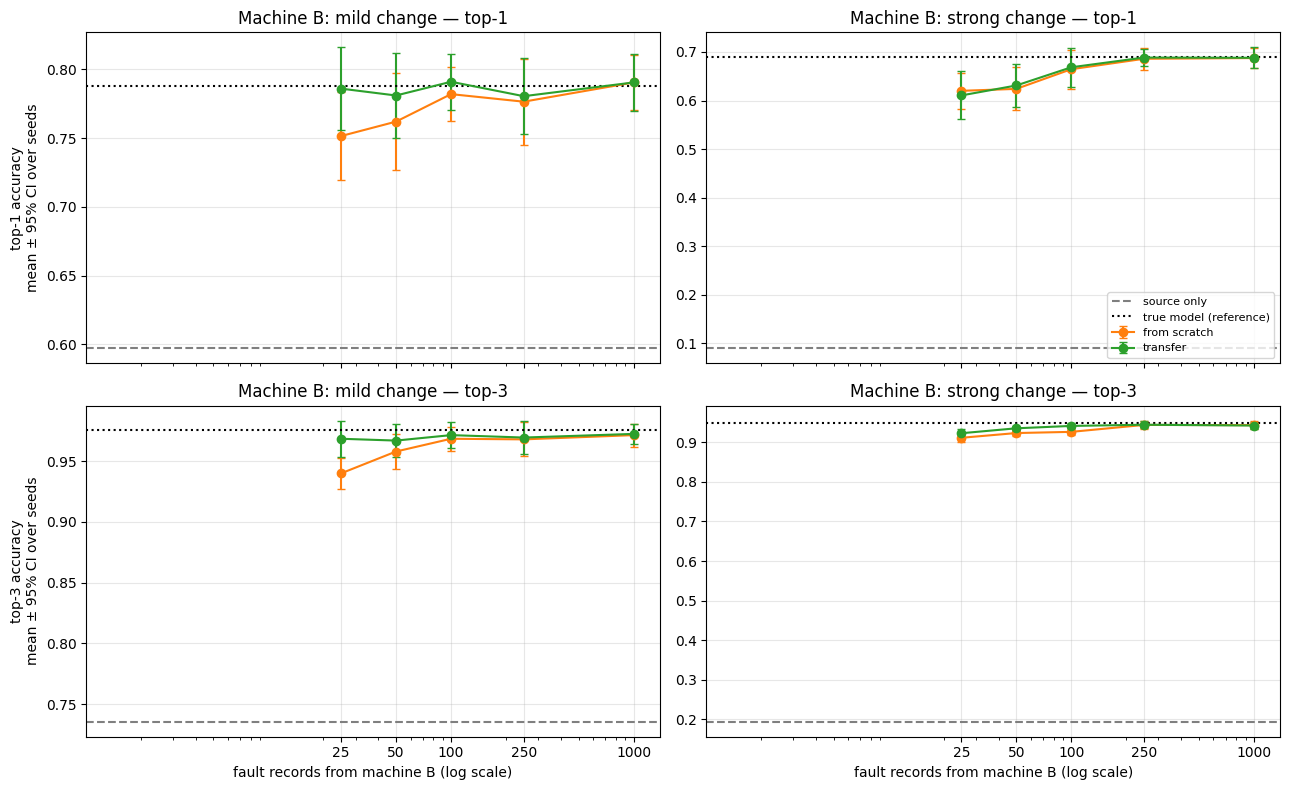

In [12]:
def diag_job(variant, seed):
    # All methods for one variant and seed, scored on the same test cases
    cases = single_fault_cases(targets[variant], N_TEST_CASES, seed=10_000 + seed)
    out = []
    for method, model in [("source only", source), ("true model (reference)", targets[variant])]:
        top1, top3, imp = evaluate_diagnosis(model, cases)
        out.append({"variant": variant, "seed": seed, "method": method, "n": 0, "top1": top1, "top3": top3, "impossible": imp})
    for n in DIAG_SIZES:
        data = simulate(targets[variant], n, seed)
        for method, learner in [("from scratch", learn_from_scratch), ("transfer", learn_with_transfer)]:
            top1, top3, imp = evaluate_diagnosis(learner(data), cases)
            out.append({"variant": variant, "seed": seed, "method": method, "n": n, "top1": top1, "top3": top3, "impossible": imp})
    return out

t0 = time.time()
diag_results = pd.DataFrame([r for rows in Parallel(n_jobs=N_JOBS)(delayed(diag_job)(v, s) for v in VARIANTS for s in SEEDS)
                             for r in rows])
print(f"Experiment 2: {len(diag_results)} evaluations in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for row, metric in enumerate(["top1", "top3"]):
    for ax, variant in zip(axes[row], VARIANTS):
        for method in ["from scratch", "transfer"]:
            g = diag_results.query("variant == @variant and method == @method").groupby("n")[metric].apply(mean_ci).unstack()
            ax.errorbar(g.index, g["mean"], yerr=g["ci"], marker="o", capsize=3, color=COLORS[method], label=method)
        for method, ls in [("source only", "--"), ("true model (reference)", ":")]:
            ref = diag_results.query("variant == @variant and method == @method")[metric].mean()
            ax.axhline(ref, ls=ls, color=COLORS[method], label=method)
        ax.set(xscale="log", title=f"Machine B: {variant} change — {'top-1' if metric == 'top1' else 'top-3'}")
        ax.set_xticks(DIAG_SIZES); ax.set_xticklabels(DIAG_SIZES); ax.grid(alpha=0.3)
        if row == 1: ax.set_xlabel("fault records from machine B (log scale)")
    axes[row][0].set_ylabel(f"{'top-1' if metric == 'top1' else 'top-3'} accuracy\nmean ± 95% CI over seeds")
axes[0][1].legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

**Result tables, experiment 2.** First, accuracy per method (mean ± 95% CI across seeds). Second, the **paired** difference *transfer − from scratch*, computed per seed on identical training data and test cases, which removes the noise both methods share.

In [13]:
diag_table = (diag_results.groupby(["variant", "method", "n"])
              .agg(top1=("top1", lambda c: fmt(*mean_ci(c), digits=3)),
                   top3=("top3", lambda c: fmt(*mean_ci(c), digits=3)),
                   impossible_share=("impossible", lambda c: f"{c.mean():.1%}")))
display(diag_table)

learned = diag_results[diag_results.method.isin(["from scratch", "transfer"])]
wide_d = learned.pivot_table(index=["variant", "n", "seed"], columns="method", values=["top1", "top3"])
diff = pd.DataFrame({m: wide_d[(m, "transfer")] - wide_d[(m, "from scratch")] for m in ["top1", "top3"]})
paired = diff.groupby(["variant", "n"]).agg(lambda d: fmt(*mean_ci(d), digits=3))
paired.columns = ["top-1: transfer − scratch", "top-3: transfer − scratch"]
display(paired)

top1           top3 impossible_share
variant method                 n                                                  
mild    from scratch           25    0.751 ± 0.032  0.940 ± 0.013             0.0%
                               50    0.762 ± 0.035  0.958 ± 0.014             0.0%
                               100   0.782 ± 0.020  0.968 ± 0.010             0.0%
                               250   0.777 ± 0.031  0.968 ± 0.014             0.0%
                               1000  0.790 ± 0.020  0.972 ± 0.009             0.0%
        source only            0     0.597 ± 0.022  0.736 ± 0.024            17.1%
        transfer               25    0.786 ± 0.030  0.968 ± 0.015             0.0%
                               50    0.781 ± 0.031  0.967 ± 0.014             0.0%
                               100   0.791 ± 0.020  0.972 ± 0.011             0.0%
                               250   0.781 ± 0.028  0.970 ± 0.014             0.0%
                               1000  0.790 ± 0.021  0.972 ± 0.008             0.0%
        true model (reference) 0     0.788 ± 0.025  0.976 ± 0.010             0.0%
strong  from scratch           25    0.620 ± 0.037  0.911 ± 0.011             0.0%
                               50    0.624 ± 0.044  0.924 ± 0.007             0.0%
                               100   0.664 ± 0.040  0.927 ± 0.008             0.0%
                               250   0.686 ± 0.022  0.944 ± 0.011             0.0%
                               1000  0.688 ± 0.021  0.944 ± 0.010             0.0%
        source only            0     0.089 ± 0.012  0.194 ± 0.017            64.4%
        transfer               25    0.610 ± 0.049  0.923 ± 0.011             0.0%
                               50    0.631 ± 0.045  0.935 ± 0.006             0.0%
                               100   0.669 ± 0.040  0.942 ± 0.006             0.0%
                               250   0.689 ± 0.018  0.945 ± 0.008             0.0%
                               1000  0.688 ± 0.021  0.943 ± 0.009             0.0%
        true model (reference) 0     0.691 ± 0.021  0.949 ± 0.011             0.0%

top-1: transfer − scratch top-3: transfer − scratch
variant n                                                       
mild    25               0.035 ± 0.021             0.028 ± 0.009
        50               0.019 ± 0.011             0.009 ± 0.006
        100              0.009 ± 0.008             0.003 ± 0.003
        250              0.004 ± 0.006             0.001 ± 0.003
        1000             0.000 ± 0.002             0.001 ± 0.002
strong  25              -0.010 ± 0.031             0.011 ± 0.008
        50               0.007 ± 0.015             0.012 ± 0.009
        100              0.004 ± 0.009             0.015 ± 0.006
        250              0.003 ± 0.009             0.001 ± 0.005
        1000             0.001 ± 0.001            -0.001 ± 0.002

## 6. Experiment 3: how much should machine A be trusted?

The prior strength `PRIOR_ESS` is the number of virtual records A's model is worth for each parent combination. A weak prior wastes A's knowledge; a strong prior makes the model cling to A's numbers even where B is different. The best setting should depend on how different B is, which is exactly the question an engineer faces when deploying a model to a new machine.

Training size is fixed at 50 records; prior strength is swept from 0.3 to 1000. The plot and the table use parameter error. Choosing the strength in practice, without B's true model, is discussed in section 8.

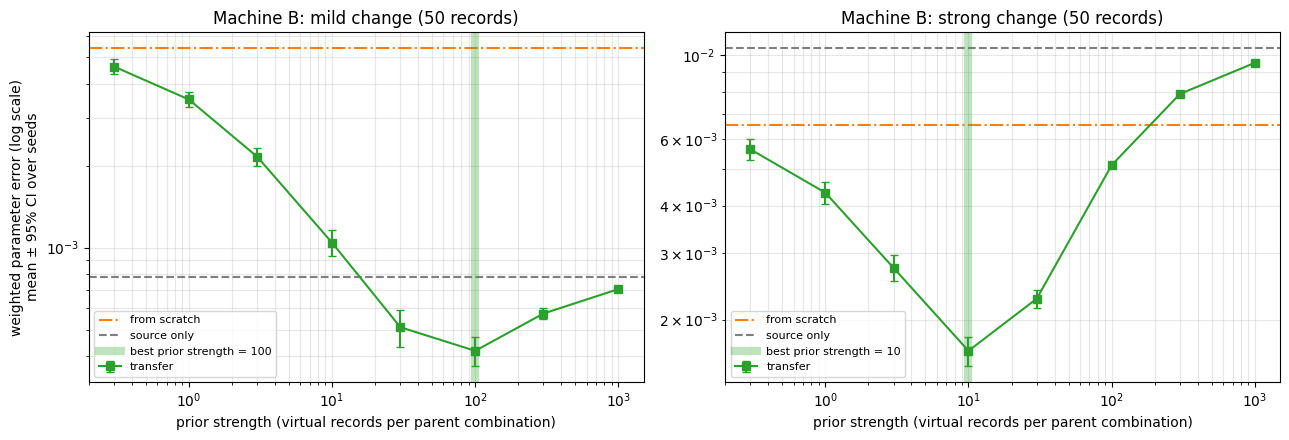

variant,mild,strong
ess,,
0.3,0.00463 ± 0.00030,0.00563 ± 0.00035
1.0,0.00350 ± 0.00022,0.00433 ± 0.00029
3.0,0.00216 ± 0.00016,0.00274 ± 0.00022
10.0,0.00104 ± 0.00012,0.00166 ± 0.00015
30.0,0.00051 ± 0.00008,0.00227 ± 0.00012
100.0,0.00042 ± 0.00005,0.00512 ± 0.00010
300.0,0.00057 ± 0.00003,0.00789 ± 0.00005
1000.0,0.00070 ± 0.00001,0.00953 ± 0.00002
from scratch (reference),0.00541,0.00652


In [14]:
SWEEP_N, SWEEP_ESS = 50, [0.3, 1, 3, 10, 30, 100, 300, 1000]

def sweep_job(variant, ess, seed):
    data = simulate(targets[variant], SWEEP_N, seed)
    return {"variant": variant, "ess": ess, "seed": seed,
            "error": weighted_error(learn_with_transfer(data, ess), targets[variant], WEIGHTS[variant])}

sweep = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(sweep_job)(v, e, s)
                                             for v in VARIANTS for e in SWEEP_ESS for s in SEEDS))
scratch_at_sweep_n = {v: param_results.query("variant == @v and method == 'from scratch' and n == @SWEEP_N")["error"].mean()
                      for v in VARIANTS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, variant in zip(axes, VARIANTS):
    g = sweep.query("variant == @variant").groupby("ess")["error"].apply(mean_ci).unstack()
    ax.errorbar(g.index, g["mean"], yerr=g["ci"], marker="s", capsize=3, color=COLORS["transfer"], label="transfer")
    ax.axhline(scratch_at_sweep_n[variant], color=COLORS["from scratch"], ls="-.", label="from scratch")
    ax.axhline(source_error[variant], color=COLORS["source only"], ls="--", label="source only")
    best = g["mean"].idxmin()
    ax.axvline(best, color="tab:green", alpha=0.3, lw=6, label=f"best prior strength = {best:g}")
    ax.set(xscale="log", yscale="log", title=f"Machine B: {variant} change ({SWEEP_N} records)",
           xlabel="prior strength (virtual records per parent combination)")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
axes[0].set_ylabel("weighted parameter error (log scale)\nmean ± 95% CI over seeds")
plt.tight_layout(); plt.show()

sweep_table = sweep.groupby(["ess", "variant"])["error"].apply(lambda c: fmt(*mean_ci(c), digits=5)).unstack()
sweep_table.loc["from scratch (reference)"] = [f"{scratch_at_sweep_n[v]:.5f}" for v in sweep_table.columns]
sweep_table.loc["source only (reference)"] = [f"{source_error[v]:.5f}" for v in sweep_table.columns]
sweep_table

## 7. Findings

The text below is **generated from the result tables above** each time the notebook runs. A difference is called *statistically clear* when its 95% confidence interval across seeds excludes zero.

In [15]:
def ci_of(series):
    s = mean_ci(series); return s["mean"], s["ci"]

def verdict(m, ci):
    if m - ci > 0: return "statistically clear gain"
    if m + ci < 0: return "statistically clear loss"
    return "within noise"

lines = []
cap = lambda s: s[0].upper() + s[1:]

# 1. Source only
f1 = []
for v in VARIANTS:
    so = diag_results.query("variant == @v and method == 'source only'")
    ref = diag_results.query("variant == @v and method == 'true model (reference)'")
    m, ci = ci_of(so["top1"]); r, rci = ci_of(ref["top1"])
    f1.append(f"on the **{v}** variant its top-1 accuracy is **{m:.0%} ± {ci:.0%}** against **{r:.0%} ± {rci:.0%}** "
              f"for the true model, and it finds {so['impossible'].mean():.1%} of real cases impossible "
              f"(parameter error {source_error[v]:.5f})")
lines.append("**1. Reusing the old model unchanged.** " + cap("; ".join(f1)) + ".")

# 2. Parameter recovery
f2 = []
for v in VARIANTS:
    r = wide.loc[v].groupby("n")["ratio"].mean()
    t_mean = param_results.query("variant == @v and method == 'transfer'").groupby("n")["error"].mean()
    better_than_source = [n for n in TRAIN_SIZES if t_mean[n] < source_error[v]]
    beats = (f"transfer beats the unchanged old model from {min(better_than_source)} records on"
             if better_than_source else "transfer never beats the unchanged old model in this range")
    f2.append(f"on the **{v}** variant transfer's error is **{r.iloc[0]:.2f}×** that of learning from scratch at "
              f"{r.index[0]} records and {r.iloc[-1]:.2f}× at {r.index[-1]} records; {beats}")
lines.append("**2. Recovering the new machine's probabilities.** " + cap("; ".join(f2)) + ".")

# 3. Diagnosis
f3 = []
for v in VARIANTS:
    parts = []
    for n in DIAG_SIZES:
        d1 = ci_of(diff.loc[(v, n), "top1"]); d3 = ci_of(diff.loc[(v, n), "top3"])
        parts.append(f"{n}: top-1 {d1[0]*100:+.1f} ± {d1[1]*100:.1f} pts ({verdict(*d1)}), "
                     f"top-3 {d3[0]*100:+.1f} ± {d3[1]*100:.1f} pts ({verdict(*d3)})")
    ref1 = diag_results.query("variant == @v and method == 'true model (reference)'")["top1"].mean()
    last_n = DIAG_SIZES[-1]
    last = diag_results.query("variant == @v and method in ['from scratch', 'transfer'] and n == @last_n")
    gap = ref1 - last.groupby("method")["top1"].mean()
    f3.append(f"On the **{v}** variant (transfer − scratch, by number of records): " + "; ".join(parts) +
              f". At {DIAG_SIZES[-1]} records both are within {gap.abs().max()*100:.1f} points of the true model's top-1.")
lines.append("**3. Diagnosis.** " + " ".join(f3))

# 4. Prior strength
f4 = []
for v in VARIANTS:
    g = sweep.query("variant == @v").groupby("ess")["error"].mean()
    best, worst_ess = g.idxmin(), max(SWEEP_ESS)
    over = ("worse than learning from scratch" if g[worst_ess] > scratch_at_sweep_n[v]
            else "still better than learning from scratch")
    f4.append(f"on the **{v}** variant the best prior strength is **{best:g}** (error {g[best]:.5f}, versus "
              f"{scratch_at_sweep_n[v]:.5f} from scratch and {source_error[v]:.5f} for the unchanged old model); "
              f"at strength {worst_ess:g} transfer is {over} ({g[worst_ess]:.5f})")
lines.append(f"**4. How much to trust the old machine ({SWEEP_N} records).** " + cap("; ".join(f4)) + ".")

display(Markdown("\n\n".join(lines)))

**1. Reusing the old model unchanged.** On the **mild** variant its top-1 accuracy is **60% ± 2%** against **79% ± 2%** for the true model, and it finds 17.1% of real cases impossible (parameter error 0.00078); on the **strong** variant its top-1 accuracy is **9% ± 1%** against **69% ± 2%** for the true model, and it finds 64.4% of real cases impossible (parameter error 0.01042).

**2. Recovering the new machine's probabilities.** On the **mild** variant transfer's error is **0.16×** that of learning from scratch at 25 records and 0.45× at 5000 records; transfer beats the unchanged old model from 100 records on; on the **strong** variant transfer's error is **0.22×** that of learning from scratch at 25 records and 0.58× at 5000 records; transfer beats the unchanged old model from 25 records on.

**3. Diagnosis.** On the **mild** variant (transfer − scratch, by number of records): 25: top-1 +3.5 ± 2.1 pts (statistically clear gain), top-3 +2.8 ± 0.9 pts (statistically clear gain); 50: top-1 +1.9 ± 1.1 pts (statistically clear gain), top-3 +0.9 ± 0.6 pts (statistically clear gain); 100: top-1 +0.9 ± 0.8 pts (statistically clear gain), top-3 +0.3 ± 0.3 pts (within noise); 250: top-1 +0.4 ± 0.6 pts (within noise), top-3 +0.1 ± 0.3 pts (within noise); 1000: top-1 +0.0 ± 0.2 pts (within noise), top-3 +0.1 ± 0.2 pts (within noise). At 1000 records both are within 0.2 points of the true model's top-1. On the **strong** variant (transfer − scratch, by number of records): 25: top-1 -1.0 ± 3.1 pts (within noise), top-3 +1.1 ± 0.8 pts (statistically clear gain); 50: top-1 +0.7 ± 1.5 pts (within noise), top-3 +1.2 ± 0.9 pts (statistically clear gain); 100: top-1 +0.4 ± 0.9 pts (within noise), top-3 +1.5 ± 0.6 pts (statistically clear gain); 250: top-1 +0.3 ± 0.9 pts (within noise), top-3 +0.1 ± 0.5 pts (within noise); 1000: top-1 +0.1 ± 0.1 pts (within noise), top-3 -0.1 ± 0.2 pts (within noise). At 1000 records both are within 0.3 points of the true model's top-1.

**4. How much to trust the old machine (50 records).** On the **mild** variant the best prior strength is **100** (error 0.00042, versus 0.00541 from scratch and 0.00078 for the unchanged old model); at strength 1000 transfer is still better than learning from scratch (0.00070); on the **strong** variant the best prior strength is **10** (error 0.00166, versus 0.00652 from scratch and 0.01042 for the unchanged old model); at strength 1000 transfer is worse than learning from scratch (0.00953).

**Interpretation.** Parameter error and diagnosis accuracy answer different questions. Transfer can recover the full set of probabilities much better while improving diagnosis only modestly, because ranking faults depends mainly on a few influential tables, and with complete training records those are learned quickly from B's own data. The prior-strength sweep shows the central trade-off of transfer: the more the new machine differs, the less the old model should be trusted, and over-trusting can be worse than ignoring it.

## 8. Limitations and next steps

- **Synthetic machine differences.** The variants are controlled perturbations chosen to isolate two mechanisms (fault-rate shifts and sensor noise). Conclusions about *when* transfer helps should be validated on a pair of real machine variants, whose differences may be structured (correlated drift, systematic sensor bias) rather than random.
- **Structural transfer.** Both machines share one graph. A real new variant may add or remove components. Next step: structure learning (hill climbing with BIC) seeded with, or penalised for deviating from, machine A's graph, evaluated by structural Hamming distance to B's true graph.
- **Incomplete fault logs.** Training records here are fully observed. Real maintenance logs rarely record every internal state, so learning would use EM with the same Dirichlet prior, which likely makes transfer *more* valuable.
- **Choosing the prior strength without B's true model.** The sweep scores each setting against the true model. In practice it would be chosen by cross-validated likelihood on B's own records, or per node (trusting A only where B's data agrees with it).
- **Observation set and the single-fault assumption.** Diagnosis observes every symptom and test and assumes exactly one active fault, matching how the test cases are generated. Real diagnosis starts from a few symptoms, chooses the next test by expected information gain, and must allow for multiple simultaneous faults.